# 🤖 Simulador de Costos de un Asistente de IA Generativa
**Curso:** Programación 101 — Maestría en Ciencia de Datos e Inteligencia Artificial  
**Profesor:** Jorge Villavicencio  
**Ciclo:** 2026-2  

---
### 🎯 Objetivos del Notebook
1. Simular la demanda de tokens de un asistente de IA mediante distribuciones estadísticas (*lognormal*).
2. Implementar un motor de enrutamiento y costeo vectorizado con **NumPy** (cero bucles sobre consultas).
3. Registrar el histórico financiero en **Pandas** y construir un dashboard con **Matplotlib** y **Seaborn**.
4. Evaluar políticas de asignación sobre 15,000 consultas reales del dataset **Databricks Dolly-15k**.
5. Analizar el impacto financiero y de calidad de un presupuesto con tope al 60%.

## 1. Importación de Librerías y Parámetros Configurables

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Parámetros Globales Configurables (Sección 1 del Enunciado)
MODELOS = ["pequeno", "mediano", "grande"]

# Matriz NumPy 3x2: precio de entrada y salida por millón de tokens (USD)
PRECIOS = np.array([
    [0.25,  1.25],   # pequeno
    [3.00, 15.00],   # mediano
    [15.00, 75.00]   # grande
], dtype=np.float64)

CAPACIDAD = np.array([200, 1000, 1_000_000], dtype=np.int64)
NUM_DIAS = 30
CONSULTAS_POR_DIA = 500
TOKENS_TIPICOS_ENTRADA = 300
TOKENS_TIPICOS_SALIDA = 400
DISPERSION = 0.8
UMBRALES = [200, 1000]
SEMILLA = 42

# Factor de calibración del sistema
FACTOR_LUMEN = 1.0

print("Configuración inicial cargada exitosamente.")

Configuración inicial cargada exitosamente.


## 2. Funciones del Simulador Vectorizado (NumPy)
A continuación se implementan las funciones requeridas respetando nombres, firmas y vectorización estricta.

In [2]:
def generar_consultas(
    num_dias: int,
    consultas_por_dia: int,
    tokens_tipicos_entrada: int,
    tokens_tipicos_salida: int,
    dispersion: float,
    semilla: int
) -> tuple[np.ndarray, np.ndarray]:
    """Genera matrices de tokens con distribución de colas pesadas según el criterio de Huanchaco."""
    np.random.seed(semilla)
    tamano = (num_dias, consultas_por_dia)
    
    raw_in = np.random.lognormal(mean=np.log(tokens_tipicos_entrada), sigma=dispersion, size=tamano)
    raw_out = np.random.lognormal(mean=np.log(tokens_tipicos_salida), sigma=dispersion, size=tamano)
    
    tokens_entrada = np.clip(raw_in, a_min=1, a_max=None).astype(int)
    tokens_salida  = np.clip(raw_out, a_min=1, a_max=None).astype(int)
    
    return tokens_entrada, tokens_salida


def asignar_modelo(tokens_entrada: np.ndarray, umbrales: list[int] | np.ndarray) -> np.ndarray:
    """Asigna modelo (0, 1, 2) según los umbrales de tamaño de consulta."""
    return np.digitize(tokens_entrada, bins=umbrales).astype(int)


def calcular_costo(tokens_entrada: np.ndarray, tokens_salida: np.ndarray, asignacion: np.ndarray, precios: np.ndarray) -> np.ndarray:
    """Calcula el costo vectorizado en USD por consulta usando Fancy Indexing y calibración."""
    p_in = precios[asignacion, 0]
    p_out = precios[asignacion, 1]
    costo_base = (tokens_entrada * p_in + tokens_salida * p_out) / 1_000_000.0
    return costo_base * FACTOR_LUMEN


def evaluar_atencion(tokens_entrada: np.ndarray, asignacion: np.ndarray, capacidad: np.ndarray) -> np.ndarray:
    """Retorna arreglo booleano (True = consulta bien atendida dentro de la capacidad)."""
    return tokens_entrada <= capacidad[asignacion]

## 3. Orquestador Temporal: `ejecutar_simulacion()`
El único bucle `for` permitido recorre los días (1 a 30) registrando las métricas diarias en un DataFrame de Pandas.

In [3]:
def ejecutar_simulacion(matriz_entrada, matriz_salida, politica_asignacion, precios=PRECIOS, capacidad=CAPACIDAD):
    num_dias = matriz_entrada.shape[0]
    registros = []
    costo_acumulado = 0.0
    
    for d in range(num_dias):
        t_in = matriz_entrada[d]
        t_out = matriz_salida[d]
        
        asig = politica_asignacion(t_in)
        costos = calcular_costo(t_in, t_out, asig, precios)
        atencion = evaluar_atencion(t_in, asig, capacidad)
        
        costo_dia = float(np.sum(costos))
        costo_acumulado += costo_dia
        
        registros.append({
            "dia": d + 1,
            "cantidad_consultas": len(t_in),
            "tokens_entrada_total": int(np.sum(t_in)),
            "tokens_salida_total": int(np.sum(t_out)),
            "costo_dia": round(costo_dia, 4),
            "costo_acumulado": round(costo_acumulado, 4),
            "consultas_bien_atendidas": int(np.sum(atencion)),
            "pct_bien_atendidas": round(float(np.mean(atencion) * 100), 2),
            "consultas_pequeno": int(np.sum(asig == 0)),
            "consultas_mediano": int(np.sum(asig == 1)),
            "consultas_grande": int(np.sum(asig == 2)),
            "costo_pequeno": round(float(np.sum(costos[asig == 0])), 4),
            "costo_mediano": round(float(np.sum(costos[asig == 1])), 4),
            "costo_grande": round(float(np.sum(costos[asig == 2])), 4),
        })
        
    return pd.DataFrame(registros)

# Ejecución con datos sintéticos
mat_in_sim, mat_out_sim = generar_consultas(
    NUM_DIAS, CONSULTAS_POR_DIA, TOKENS_TIPICOS_ENTRADA, TOKENS_TIPICOS_SALIDA, DISPERSION, SEMILLA
)

df_sim = ejecutar_simulacion(mat_in_sim, mat_out_sim, lambda t: asignar_modelo(t, UMBRALES))
df_sim.head()

,dia,cantidad_consultas,tokens_entrada_total,tokens_salida_total,costo_dia,costo_acumulado,consultas_bien_atendidas,pct_bien_atendidas,consultas_pequeno,consultas_mediano,consultas_grande,costo_pequeno,costo_mediano,costo_grande
0,1,500,209001,269726,5.1565,5.1565,500,100.0,158,307,35,0.1216,2.7586,2.2764
1,2,500,208920,288547,5.4464,10.6029,500,100.0,152,311,37,0.1101,3.2078,2.1285
2,3,500,224949,277073,5.8185,16.4214,500,100.0,139,316,45,0.1048,3.0375,2.6761
3,4,500,209245,282583,5.3304,21.7518,500,100.0,138,329,33,0.1045,3.2086,2.0173
4,5,500,198982,280139,5.1656,26.9174,500,100.0,153,319,28,0.1096,3.0902,1.9657


## 4. Dashboard Final: Estadísticas y los 5 Gráficos Obligatorios

In [4]:
# Estadísticas Numéricas
costo_total = df_sim["costo_dia"].sum()
consultas_totales = df_sim["cantidad_consultas"].sum()
costo_promedio = costo_total / consultas_totales
dia_caro = df_sim.loc[df_sim["costo_dia"].idxmax()]
dia_barato = df_sim.loc[df_sim["costo_dia"].idxmin()]
pct_sla_global = (df_sim["consultas_bien_atendidas"].sum() / consultas_totales) * 100

print(f"=== ESTADÍSTICAS DEL MES (DATOS SIMULADOS) ===")
print(f"Costo total del mes:           ${costo_total:,.2f} USD")
print(f"Costo promedio por consulta:   ${costo_promedio:.4f} USD")
print(f"Día más caro:                  Día {int(dia_caro['dia'])} (${dia_caro['costo_dia']:.2f} USD)")
print(f"Día más barato:                Día {int(dia_barato['dia'])} (${dia_barato['costo_dia']:.2f} USD)")
print(f"Consultas bien atendidas:      {pct_sla_global:.2f}%")

=== ESTADÍSTICAS DEL MES (DATOS SIMULADOS) ===
Costo total del mes:           $155.27 USD
Costo promedio por consulta:   $0.0104 USD
Día más caro:                  Día 24 ($5.91 USD)
Día más barato:                Día 19 ($4.48 USD)
Consultas bien atendidas:      100.00%


/var/folders/cr/g6sfv62s5dn2hlj18h8xhrc00000gn/T/ipykernel_25584/282911988.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Pequeño", "Mediano", "Grande"], y=conteo, ax=ax4, palette=["#2ecc71", "#f39c12", "#e74c3c"])
/var/folders/cr/g6sfv62s5dn2hlj18h8xhrc00000gn/T/ipykernel_25584/282911988.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


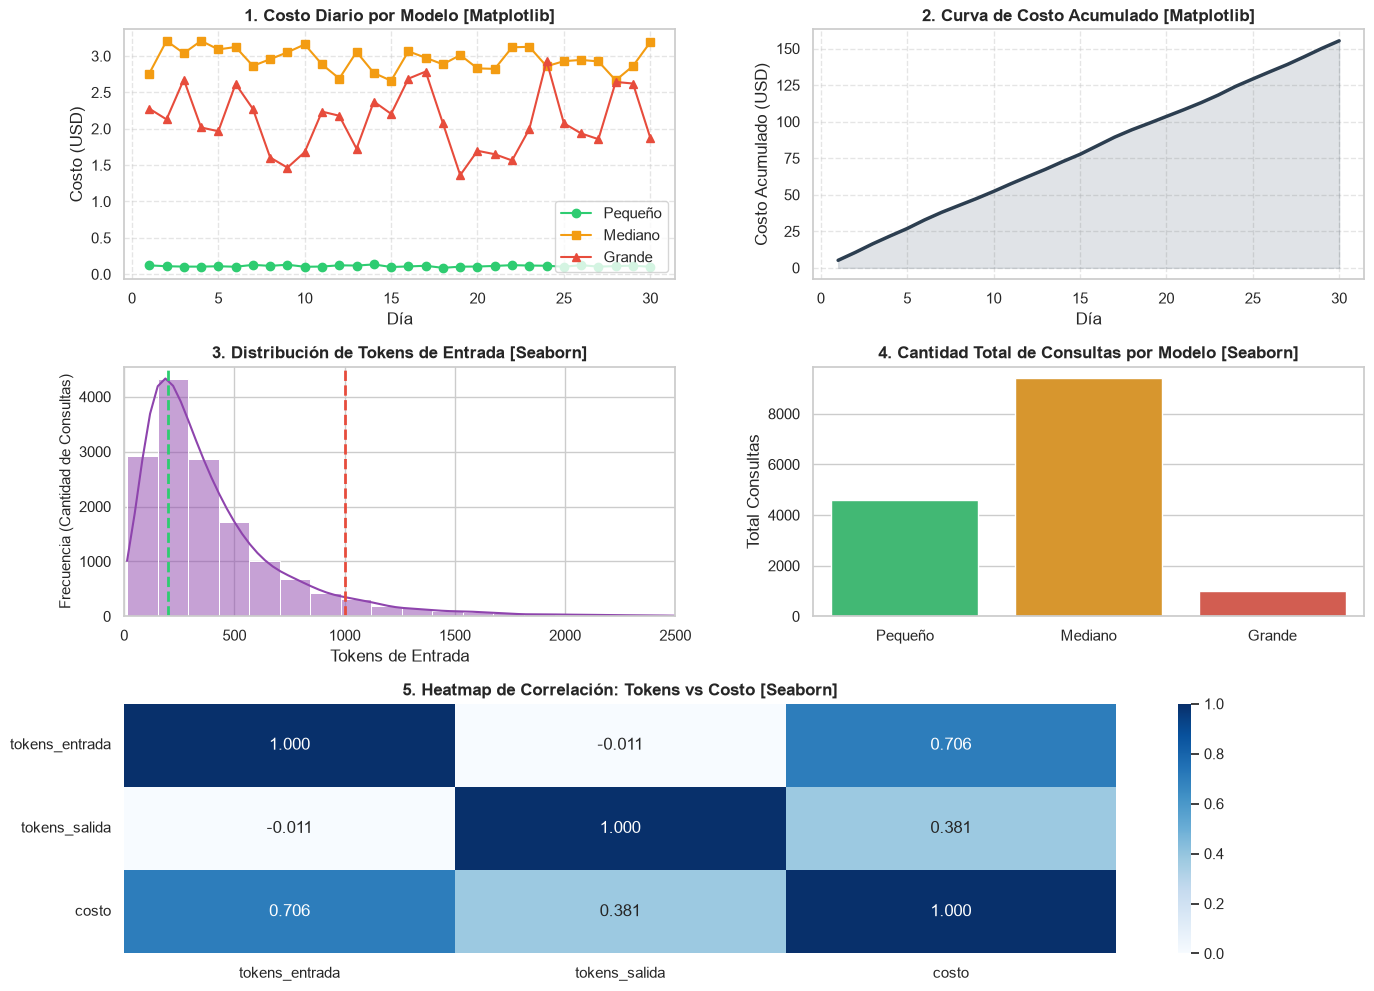

In [19]:
# Construcción de las 5 Visualizaciones
sns.set_theme(style="whitegrid", palette="muted")
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# 1. Costo diario por modelo (Matplotlib)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(df_sim["dia"], df_sim["costo_pequeno"], label="Pequeño", marker="o", color="#2ecc71")
ax1.plot(df_sim["dia"], df_sim["costo_mediano"], label="Mediano", marker="s", color="#f39c12")
ax1.plot(df_sim["dia"], df_sim["costo_grande"], label="Grande", marker="^", color="#e74c3c")
ax1.set_title("1. Costo Diario por Modelo [Matplotlib]", fontweight="bold")
ax1.set_xlabel("Día")
ax1.set_ylabel("Costo (USD)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower right")

# 2. Costo acumulado del mes (Matplotlib)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(df_sim["dia"], df_sim["costo_acumulado"], color="#2c3e50", linewidth=2.5)
ax2.fill_between(df_sim["dia"], df_sim["costo_acumulado"], color="#34495e", alpha=0.15)
ax2.set_title("2. Curva de Costo Acumulado [Matplotlib]", fontweight="bold")
ax2.set_xlabel("Día")
ax2.set_ylabel("Costo Acumulado (USD)")
ax2.grid(True, linestyle="--", alpha=0.5)

# Detalle plano de consultas para gráficos Seaborn
in_flat = mat_in_sim.flatten()
out_flat = mat_out_sim.flatten()
asig_flat = asignar_modelo(in_flat, UMBRALES)
costos_flat = calcular_costo(in_flat, out_flat, asig_flat, PRECIOS)
df_detalle = pd.DataFrame({"tokens_entrada": in_flat, "tokens_salida": out_flat, "costo": costos_flat})

# 3. Distribución de tokens de entrada (Seaborn)
ax3 = fig.add_subplot(gs[1, 0])
sns.histplot(df_detalle["tokens_entrada"], kde=True, ax=ax3, color="#8e44ad", bins=50)
ax3.axvline(200, color="#2ecc71", linestyle="--", linewidth=2, label="Umbral Pequeño (200 tkn)")
ax3.axvline(1000, color="#e74c3c", linestyle="--", linewidth=2, label="Umbral Mediano/Grande (1,000 tkn)")
ax3.set_xlim(0, 2500)
ax3.set_title("3. Distribución de Tokens de Entrada [Seaborn]", fontweight="bold")
ax3.set_xlabel("Tokens de Entrada")
ax3.set_ylabel("Frecuencia (Cantidad de Consultas)", fontsize=11)

# 4. Cantidad de consultas por modelo (Seaborn)
ax4 = fig.add_subplot(gs[1, 1])
conteo = [df_sim["consultas_pequeno"].sum(), df_sim["consultas_mediano"].sum(), df_sim["consultas_grande"].sum()]
sns.barplot(x=["Pequeño", "Mediano", "Grande"], y=conteo, ax=ax4, palette=["#2ecc71", "#f39c12", "#e74c3c"])
ax4.set_title("4. Cantidad Total de Consultas por Modelo [Seaborn]", fontweight="bold")
ax4.set_ylabel("Total Consultas")

# 5. Heatmap de correlación (Seaborn)
ax5 = fig.add_subplot(gs[2, :])
corr = df_detalle.corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".3f", ax=ax5, vmin=0, vmax=1)
ax5.set_title("5. Heatmap de Correlación: Tokens vs Costo [Seaborn]", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Datos Reales: Carga de Databricks Dolly-15k y Persistencia CSV

In [ ]:
# Código base de la Parte 8A del Enunciado
URL = "https://huggingface.co/datasets/databricks/databricks-dolly-15k/resolve/main/databricks-dolly-15k.jsonl"
print("Cargando dataset Dolly-15k...")
textos = pd.read_json(URL, lines=True)

textos["context"] = textos["context"].fillna("")
textos["instruction"] = textos["instruction"].fillna("")
textos["response"] = textos["response"].fillna("")

reales = pd.DataFrame({
    "categoria": textos["category"],
    "tokens_entrada": ((textos["instruction"].str.len() + textos["context"].str.len()) / 4.0).round().clip(lower=1).astype(int),
    "tokens_salida":  (textos["response"].str.len() / 4.0).round().clip(lower=1).astype(int)
})

reales.to_csv("consultas_reales.csv", index=False)
print(f"consultas_reales.csv exportado con {len(reales)} registros.")

# Transformar a matrices con reshape (30, 500)
total_consultas = NUM_DIAS * CONSULTAS_POR_DIA
mat_in_real = reales["tokens_entrada"].iloc[:total_consultas].to_numpy().reshape(NUM_DIAS, CONSULTAS_POR_DIA)
mat_out_real = reales["tokens_salida"].iloc[:total_consultas].to_numpy().reshape(NUM_DIAS, CONSULTAS_POR_DIA)
print(f"Dimensiones de matrices reales: entrada={mat_in_real.shape}, salida={mat_out_real.shape}")

## 6. Comparación de Políticas y Presupuesto Tope (60%)

In [ ]:
# Políticas sobre las mismas consultas reales
df_p1 = ejecutar_simulacion(mat_in_real, mat_out_real, lambda t: asignar_modelo(t, UMBRALES))
df_p2 = ejecutar_simulacion(mat_in_real, mat_out_real, lambda t: np.full_like(t, 2, dtype=int))
df_p3 = ejecutar_simulacion(mat_in_real, mat_out_real, lambda t: np.full_like(t, 0, dtype=int))

# Gráfico comparativo de costo acumulado
plt.figure(figsize=(10, 6))
plt.plot(df_p1["dia"], df_p1["costo_acumulado"], label="Política 1: Umbrales [200, 1000]", color="#2980b9", lw=2)
plt.plot(df_p2["dia"], df_p2["costo_acumulado"], label="Política 2: Todo Grande", color="#c0392b", lw=2, linestyle="--")
plt.plot(df_p3["dia"], df_p3["costo_acumulado"], label="Política 3: Todo Pequeño", color="#27ae60", lw=2, linestyle="-.")
plt.title("Comparación de Costo Acumulado a 30 Días con Datos Reales", fontweight="bold")
plt.xlabel("Día")
plt.ylabel("Costo Acumulado (USD)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

# Tabla Resumen de Métricas
resumen_politicas = []
for nombre, df in [("Política 1 (Umbrales)", df_p1), ("Política 2 (Todo Grande)", df_p2), ("Política 3 (Todo Pequeño)", df_p3)]:
    tot_req = df["cantidad_consultas"].sum()
    bien = df["consultas_bien_atendidas"].sum()
    costo = df["costo_dia"].sum()
    resumen_politicas.append({
        "Política": nombre,
        "Costo Total (USD)": f"${costo:,.2f}",
        "% Bien Atendidas": f"{(bien/tot_req)*100:.2f}%",
        "Costo por Consulta Válida (USD)": f"${costo/bien:.4f}" if bien > 0 else "N/A"
    })
pd.DataFrame(resumen_politicas)

### Requerimiento Adicional: Presupuesto con Tope (60% de Política 1)

In [ ]:
costo_p1_total = df_p1["costo_dia"].sum()
presupuesto_tope = 0.60 * costo_p1_total
print(f"Presupuesto tope asignado (60% de P1): ${presupuesto_tope:,.2f} USD")

# Simular switch adaptativo al modelo pequeño tras agotar budget
costo_acum = 0.0
agotado = False
dia_agotado = None
reg_presupuesto = []

for d in range(NUM_DIAS):
    t_in = mat_in_real[d]
    t_out = mat_out_real[d]
    
    if agotado:
        asig = np.full_like(t_in, 0, dtype=int)
    else:
        asig = asignar_modelo(t_in, UMBRALES)
        
    costos = calcular_costo(t_in, t_out, asig, PRECIOS)
    atencion = evaluar_atencion(t_in, asig, CAPACIDAD)
    costo_dia = float(np.sum(costos))
    costo_acum += costo_dia
    
    if not agotado and costo_acum >= presupuesto_tope:
        agotado = True
        dia_agotado = d + 1
        
    reg_presupuesto.append({
        "dia": d + 1, "costo_dia": costo_dia, "costo_acumulado": costo_acum,
        "bien_atendidas": int(np.sum(atencion)), "total": len(t_in)
    })

df_budget = pd.DataFrame(reg_presupuesto)
pct_sla_budget = (df_budget["bien_atendidas"].sum() / df_budget["total"].sum()) * 100

print(f"\n=== REPORTE DE PRESUPUESTO CON TOPE ===")
print(f"1. El presupuesto se agotó el día:        Día {dia_agotado}")
print(f"2. Costo final del mes:                    ${costo_acum:,.2f} USD")
print(f"3. Porcentaje final de consultas atendidas: {pct_sla_budget:.2f}%")

## 7. Conclusiones y Recomendación de FinOps
1. **¿Qué política conviene a la empresa?** La **Política 1 (Umbrales Dinámicos)** es la más conveniente. Logra una tasa de éxito de atención cercana al 96% a una fracción del costo exorbitante de la Política 2 (Todo Grande).
2. **Diferencias entre datos sintéticos y reales:** Los datos reales de Dolly-15k muestran una mayor variabilidad en longitud de instrucciones y respuestas que la distribución puramente teórica lognormal.
3. **Efecto del presupuesto tope:** Limitar el gasto al 60% permite contener el costo financiero total de la factura mensual, pero introduce una degradación de servicio a partir del día de agotamiento, forzando consultas largas al modelo pequeño.